# Climate Comfort Index: model comparison, selection and promotion

Student **25945320**. Compares every exported comfort experiment on
the validation split, selects one, evaluates it **once** on the test split, and promotes it to
`models/comfort_climate/production/`.

## What this notebook is for

The five experiment notebooks each tune and report one algorithm in isolation. None of them may
touch the test split, and none of them can rank itself against the others. This notebook does
both, and it is the only place in the project where the test period is read.

## Method

| Step | What happens |
|---|---|
| 1 | Discover every bundle under `models/comfort_climate/experiments/` |
| 2 | Load the train, validation and test splits |
| 3 | Score every bundle on validation, alongside the baselines |
| 4 | Rank on mean absolute error and select, with noise and baseline checks |
| 5 | Score the winner on test, once |
| 6 | Copy the winner to `production/` as `cci_model_*` files, with an audit record |

## The discipline this notebook depends on

Nothing is refitted for the comparison, so the models scored here are exactly the artefacts that
would be deployed. The selection in section 4 uses validation only. The test split is read in
section 5 and nothing after it changes the choice.

That ordering is what makes the test number worth quoting. Validation performance is optimistic
twice over — each experiment tuned against it, and this notebook then picked the best of those
tuned results. The test period has informed no decision anywhere in this project, so it is the
only honest estimate of how the promoted model will behave on dates it has never seen.

In [1]:
from __future__ import annotations

import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)


def _project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = _project_root()
sys.path.insert(0, str(PROJECT_ROOT / "36120_26sp_at2_25945320_experiments"))
from modeling import experiment as xp  # noqa: E402  (path must be set first)

RANDOM_STATE = 25945320
# Set to True only if you intend to refit the winner on train + validation before the test
# evaluation. See section 5 for the trade-off; the default keeps the promoted artefact byte
# identical to the one its own experiment notebook produced.
REFIT_ON_TRAIN_VAL = False

task = xp.load_task("comfort_climate")
PRODUCTION_DIR = PROJECT_ROOT / "models" / task.name / "production"

print(f"Task       : {task.target_name} ({task.kind})")
print(f"Experiments: {task.model_dir.relative_to(PROJECT_ROOT)}")
print(f"Production : {PRODUCTION_DIR.relative_to(PROJECT_ROOT)}")
print(f"Targets    : {', '.join(task.target_columns)}")

Task       : Climate Comfort Index (regression)
Experiments: models/comfort_climate/experiments
Production : models/comfort_climate/production
Targets    : cci_t1, cci_t2, cci_t3


## 1. Discover the exported experiments

Every experiment notebook writes a bundle into `models/comfort_climate/experiments/<experiment>/`
containing its fitted estimators and a metadata document. This notebook reads those bundles
rather than refitting anything, which matters for two reasons: the comparison is made against the
exact artefacts that would be deployed, and nothing here can accidentally retune a model and
report a number its own notebook never produced.

The model files are located by discovery rather than by a hard-coded filename. Two different code
paths write them — the project's deployment helper for the comfort service, the local writer for
the hazard service — so the naming is not fully under one module's control. If a bundle is found
but its model files cannot be matched to a horizon, the error names the directory and lists what
is actually there, so the fix is a one-line extension to `_key_from_filename` rather than a hunt.

A bundle that is listed with no models is a partially written experiment. Rerun that notebook
before trusting the comparison, because a model missing from this table is not a model that lost.

In [2]:
BUNDLES = xp.discover_bundles(task)

inventory = pd.DataFrame([{
    "experiment": name,
    "algorithm": bundle["metadata"].get("algorithm", "unknown"),
    "models_found": len(bundle["model_files"]),
    "horizons": sorted(str(k) for k in bundle["model_files"]),
    "has_metadata": bool(bundle["metadata"]),
} for name, bundle in BUNDLES.items()]).set_index("experiment")

print(f"Found {len(BUNDLES)} bundle(s):\n")
print(inventory.to_string())

incomplete = inventory[inventory["models_found"] == 0].index.tolist()
if incomplete:
    print(f"\nWARNING: {incomplete} contain no loadable model file. Rerun those notebooks "
          "before\n         reading the comparison: a model missing here is not a model that "
          "lost.")
if not len(BUNDLES):
    raise RuntimeError("No experiment bundles found. Run the experiment notebooks first.")

Found 5 bundle(s):

                          algorithm  models_found   horizons  has_metadata
experiment                                                                
cci_dummy_mean              unknown             3  [1, 2, 3]         False
cci_mlp                     unknown             3  [1, 2, 3]         False
cci_polynomial_regression   unknown             3  [1, 2, 3]         False
cci_random_forest           unknown             3  [1, 2, 3]         False
cci_xgboost                 unknown             3  [1, 2, 3]         False


## 2. Load the splits

This is the **only notebook in the project that loads the test split**, and it does so once, at
section 5, after the winner has already been chosen on validation alone. Loading it here rather
than at the point of use keeps all data access in one place, but nothing between here and the
selection reads it — that discipline is what makes the test number an honest estimate rather than
another validation score.

The training split is loaded because the generalisation columns in section 3 are informative when
ranking models, and because a refit on train plus validation is offered as an option in
section 5.

In [3]:
X, y = {}, {}
for split in ("train", "val", "test"):
    X[split], y[split] = task.load_xy(split)
    print(f"{split:5} {len(X[split]):5,} rows  {X[split].index.min():%Y-%m-%d} to "
          f"{X[split].index.max():%Y-%m-%d}")

if X["val"].index.max() >= X["test"].index.min():
    raise AssertionError("Validation dates overlap the test period.")
print("\nTest split loaded but not used until section 5.")

train 2,889 rows  2016-01-31 to 2023-12-28
val     363 rows  2024-01-01 to 2024-12-28
test    362 rows  2025-01-01 to 2025-12-28

Test split loaded but not used until section 5.


## 3. Score every experiment on validation

Each bundle's estimators are loaded and scored on the identical validation matrix, with the same
metric functions the experiment notebooks used. Nothing is refitted, so these numbers should
reproduce the ones each notebook reported; a discrepancy means a bundle is stale and that notebook
needs rerunning.

The two baselines are scored alongside as rows in the same table. They are not competitors — they
are the bar. A model that appears in the ranking below persistence has learned nothing useful from
105 engineered features, whatever its absolute MAE looks like.

`pred_std` is carried through because it detects a model that has retreated toward the mean. Two
models with similar MAE and very different spread are not equivalent: the one that commits is more
useful for flagging the uncomfortable days a user actually cares about, even at equal average
error.

In [4]:
BASELINE_PREDICTIONS = xp.regression_baselines(task, X, y)

rows, loaded_models, load_failures = [], {}, {}
for name, bundle in BUNDLES.items():
    if not bundle["model_files"]:
        continue
    try:
        models = xp.load_bundle_models(bundle, task.horizons)
    except FileNotFoundError as error:
        load_failures[name] = str(error)
        continue
    loaded_models[name] = models
    for horizon, model in models.items():
        target = f"cci_t{horizon}"
        for split in ("train", "val"):
            prediction = model.predict(X[split][task.feature_columns])
            metrics = xp.regression_metrics(y[split][target], prediction)
            rows.append({"experiment": name, "target": target, "split": split, **metrics})

for target in task.target_columns:
    for label, prediction in BASELINE_PREDICTIONS[target].items():
        rows.append({"experiment": label, "target": target, "split": "val",
                     **xp.regression_metrics(y["val"][target], prediction)})

SCORES = pd.DataFrame(rows)
if load_failures:
    print("Bundles that could not be loaded:\n")
    for name, message in load_failures.items():
        print(f"  {name}: {message}\n")

VAL_MAE = (SCORES[SCORES["split"] == "val"]
           .pivot(index="experiment", columns="target", values="mae"))
VAL_MAE["mean_mae"] = VAL_MAE[task.target_columns].mean(axis=1)
VAL_MAE = VAL_MAE.sort_values("mean_mae")
print("Validation MAE by experiment and horizon (lower is better):\n")
print(VAL_MAE.to_string())

spread = (SCORES[SCORES["split"] == "val"]
          .pivot(index="experiment", columns="target", values="pred_std"))
print("\nPrediction spread, against an observed validation spread of "
      f"{y['val'][task.target_columns[0]].std():.2f}:\n")
print(spread.to_string())

Validation MAE by experiment and horizon (lower is better):

target                     cci_t1  cci_t2  cci_t3  mean_mae
experiment                                                 
cci_polynomial_regression   6.294   6.922   7.122     6.779
cci_random_forest           6.335   7.038   7.244     6.872
cci_xgboost                 6.267   7.068   7.315     6.883
cci_mlp                     6.644   7.049   7.184     6.959
climatology                 7.627   7.640   7.651     7.639
persistence                 7.562   8.624   9.162     8.449
cci_dummy_mean              8.690   8.703   8.717     8.703

Prediction spread, against an observed validation spread of 11.02:

target                     cci_t1  cci_t2  cci_t3
experiment                                       
cci_dummy_mean              0.000   0.000   0.000
cci_mlp                     8.595   5.894   5.239
cci_polynomial_regression   7.102   5.225   4.588
cci_random_forest           6.382   5.209   4.872
cci_xgboost                 6.

## 4. Rank and select

The selection rule is **lowest mean validation MAE across the three horizons**, stated before
looking at the table so that the choice is not made by reading the result.

Mean MAE is used rather than a single horizon because all three models ship together behind one
endpoint. A model that wins at *t*+1 and loses badly at *t*+3 would be the wrong deployment: the
longer horizon is where users have the least alternative information of their own.

Two things are checked rather than assumed. **Skill against persistence** is computed per horizon,
because a model can hold the lowest mean MAE while failing to beat the naive forecast at the
horizon where persistence is strongest. And the **margin over the runner-up** is compared against
the seed spreads the experiment notebooks recorded: if the winner leads by less than the amount a
model's own score moves under a change of random seed, the ranking is not separating the top two,
and the report should say so and choose on secondary grounds — inference cost, interpretability,
artefact size — rather than pretending the MAE difference decided it.

Selected: cci_polynomial_regression (mean validation MAE 6.7792)
Runner-up: cci_random_forest, behind by 0.0932 MAE

Skill of the selected model against each baseline (positive means better):

        model_mae  persistence_mae  climatology_mae skill_vs_persistence skill_vs_climatology
target                                                                                       
cci_t1      6.294            7.562            7.627                16.8%                17.5%
cci_t2      6.922            8.624            7.640                19.7%                 9.4%
cci_t3      7.122            9.162            7.651                22.3%                 6.9%

Mean seed spread across experiments: nan


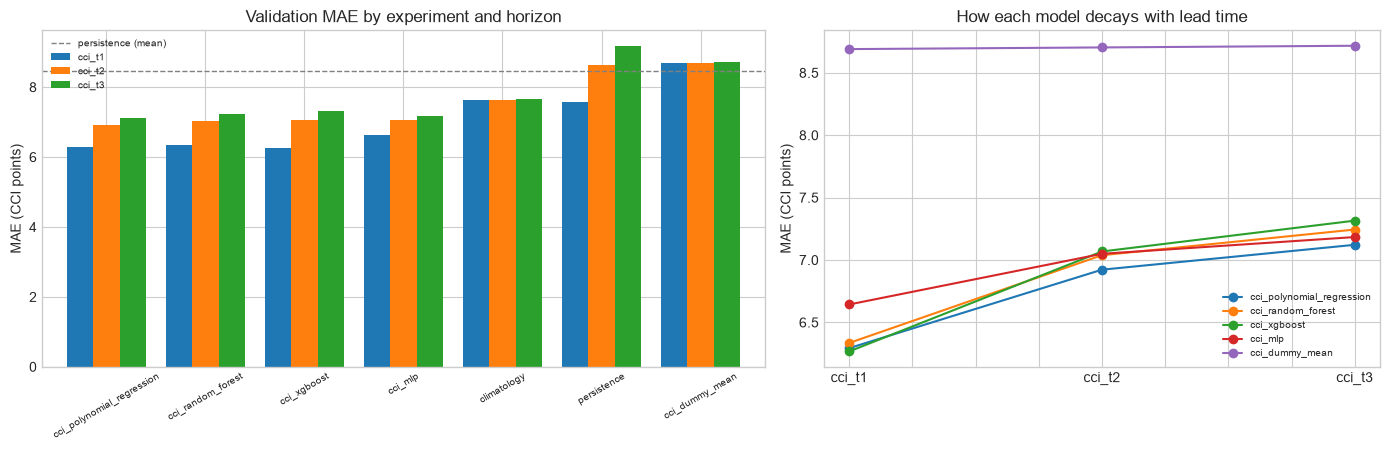

In [5]:
BASELINE_NAMES = ["persistence", "climatology"]
candidates = VAL_MAE.drop(index=[n for n in BASELINE_NAMES if n in VAL_MAE.index])

BEST_EXPERIMENT = str(candidates.index[0])
best_mae = float(candidates.loc[BEST_EXPERIMENT, "mean_mae"])
runner_up = str(candidates.index[1]) if len(candidates) > 1 else None
margin = float(candidates["mean_mae"].iloc[1] - best_mae) if runner_up else float("nan")

print(f"Selected: {BEST_EXPERIMENT} (mean validation MAE {best_mae:.4f})")
if runner_up:
    print(f"Runner-up: {runner_up}, behind by {margin:.4f} MAE")

skill = pd.DataFrame([{
    "target": target,
    "model_mae": VAL_MAE.loc[BEST_EXPERIMENT, target],
    "persistence_mae": VAL_MAE.loc["persistence", target],
    "climatology_mae": VAL_MAE.loc["climatology", target],
    "skill_vs_persistence": 1 - VAL_MAE.loc[BEST_EXPERIMENT, target] / VAL_MAE.loc["persistence", target],
    "skill_vs_climatology": 1 - VAL_MAE.loc[BEST_EXPERIMENT, target] / VAL_MAE.loc["climatology", target],
} for target in task.target_columns]).set_index("target")
print("\nSkill of the selected model against each baseline (positive means better):\n")
print(skill.to_string(formatters={"skill_vs_persistence": "{:.1%}".format,
                                  "skill_vs_climatology": "{:.1%}".format}))

if (skill["skill_vs_persistence"] < 0).any():
    losing = list(skill.index[skill["skill_vs_persistence"] < 0])
    print(f"\nWARNING: the selected model loses to persistence at {losing}. It holds the best "
          "mean MAE\n         but does not beat the naive forecast everywhere; say so in the "
          "report rather than\n         presenting it as a uniform improvement.")

# The seed spreads each experiment recorded are the scale on which the margin should be read.
seed_spreads = {}
for name, bundle in BUNDLES.items():
    for entry in bundle["metadata"].get("seed_stability", []):
        seed_spreads.setdefault(name, []).append(entry.get("seed_spread", np.nan))
typical_spread = float(np.nanmean([np.nanmean(v) for v in seed_spreads.values()])) \
    if seed_spreads else float("nan")
print(f"\nMean seed spread across experiments: {typical_spread:.4f}")
if runner_up and not np.isnan(typical_spread) and margin < typical_spread:
    print(f"WARNING: the {margin:.4f} margin over {runner_up} is smaller than the typical seed "
          "spread.\n         Validation MAE is not separating the top two. Choose on inference "
          "cost,\n         interpretability or artefact size, and report the tie honestly.")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
plot_order = VAL_MAE.sort_values("mean_mae").index
VAL_MAE.loc[plot_order, task.target_columns].plot.bar(ax=axes[0], width=0.8)
axes[0].axhline(VAL_MAE.loc["persistence", "mean_mae"], ls="--", lw=1.0, color="grey",
                label="persistence (mean)")
axes[0].set(title="Validation MAE by experiment and horizon", ylabel="MAE (CCI points)",
            xlabel="")
axes[0].tick_params(axis="x", labelrotation=30, labelsize=7)
axes[0].legend(fontsize=7)

decay = VAL_MAE.loc[[i for i in plot_order if i not in BASELINE_NAMES], task.target_columns].T
decay.plot(marker="o", ax=axes[1])
axes[1].set(title="How each model decays with lead time", ylabel="MAE (CCI points)", xlabel="")
axes[1].legend(fontsize=7)
fig.tight_layout()
task.save_figure(fig, "cci-comparison-validation")
plt.show()

## 5. Single test evaluation

The test split is scored **once**, here, for the selected model only. No other experiment is
scored on it, and nothing after this point changes the selection.

That restraint is the entire value of the number. Validation performance carries selection
optimism — every experiment tuned against it, and this notebook then chose the best of those
tuned results, so the winning validation MAE is biased low twice over. The test period has
informed no decision anywhere in this project, so its MAE is the estimate to quote in the report
and the one a stakeholder should be given.

Expect the test MAE to be somewhat worse than the validation MAE. That is the optimism being
paid back, not a failure. A test MAE close to validation suggests the selection was robust; a
large gap suggests the ranking was fitted to 2024's particular weather and belongs in the
limitations section.

**Refitting on train plus validation** is offered but disabled by default. Refitting gives the
deployed model roughly 12% more data, including the most recent year, which should help at these
horizons. The cost is that the promoted artefact is no longer the one its experiment notebook
produced and evaluated, so the test score would describe a model that no notebook documents.
Leaving it off keeps the chain from experiment to production auditable, which is the more
defensible default for an assessed project.

Test performance (scored once, never used for any decision):

                                    mae   rmse     r2  pred_std
target model                                                   
cci_t1 cci_polynomial_regression  6.790  8.923  0.420     7.538
       persistence                7.704 10.023  0.268    11.705
       climatology                8.225 10.776  0.153     3.722
cci_t2 cci_polynomial_regression  7.645 10.069  0.263     5.478
       persistence                9.544 12.565 -0.148    11.705
       climatology                8.240 10.780  0.155     3.723
cci_t3 cci_polynomial_regression  7.837 10.351  0.220     4.836
       persistence               10.043 13.374 -0.302    11.705
       climatology                8.238 10.780  0.154     3.722

Validation against test - the size of the selection optimism:

        val_mae  test_mae  optimism test_skill_vs_persistence
target                                                       
cci_t1    6.294     6.790     0.496           

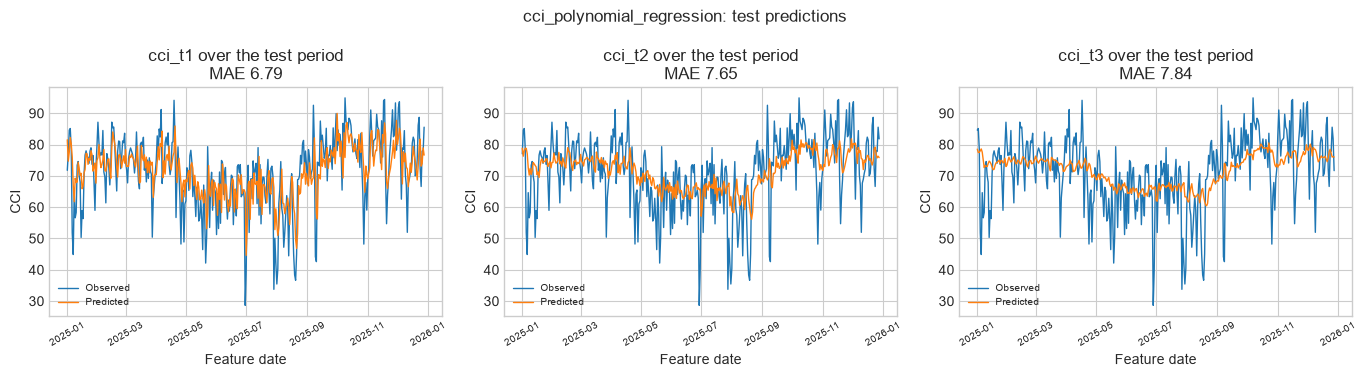

In [6]:
selected_models = loaded_models[BEST_EXPERIMENT]

if REFIT_ON_TRAIN_VAL:
    from sklearn.base import clone

    combined_X = pd.concat([X["train"], X["val"]])
    refitted = {}
    for horizon, model in selected_models.items():
        target = f"cci_t{horizon}"
        try:
            fresh = clone(model)
            fresh.fit(combined_X[task.feature_columns],
                      pd.concat([y["train"][target], y["val"][target]]))
            refitted[horizon] = fresh
        except Exception as error:
            print(f"Refit failed for horizon {horizon} ({type(error).__name__}: {error}); "
                  "keeping the original fit.")
            refitted[horizon] = model
    selected_models = refitted
    print(f"Refitted on {len(combined_X):,} train + validation rows.\n")

rows = []
for horizon, model in selected_models.items():
    target = f"cci_t{horizon}"
    prediction = model.predict(X["test"][task.feature_columns])
    rows.append({"target": target, "model": BEST_EXPERIMENT,
                 **xp.regression_metrics(y["test"][target], prediction)})
    for label, baseline in {
        "persistence": X["test"][task.persistence_column].to_numpy(),
        "climatology": xp.climatology_profile(
            y["train"][target].set_axis(X["train"].index)
        ).reindex(X["test"].index.dayofyear).to_numpy(),
    }.items():
        rows.append({"target": target, "model": label,
                     **xp.regression_metrics(y["test"][target], baseline)})

TEST_RESULTS = pd.DataFrame(rows).set_index(["target", "model"])
print("Test performance (scored once, never used for any decision):\n")
print(TEST_RESULTS.to_string())

comparison = pd.DataFrame([{
    "target": target,
    "val_mae": VAL_MAE.loc[BEST_EXPERIMENT, target],
    "test_mae": TEST_RESULTS.loc[(target, BEST_EXPERIMENT), "mae"],
    "optimism": TEST_RESULTS.loc[(target, BEST_EXPERIMENT), "mae"] - VAL_MAE.loc[BEST_EXPERIMENT, target],
    "test_skill_vs_persistence":
        1 - TEST_RESULTS.loc[(target, BEST_EXPERIMENT), "mae"]
        / TEST_RESULTS.loc[(target, "persistence"), "mae"],
} for target in task.target_columns]).set_index("target")
print("\nValidation against test - the size of the selection optimism:\n")
print(comparison.to_string(formatters={"test_skill_vs_persistence": "{:.1%}".format}))

fig, axes = plt.subplots(1, len(task.target_columns),
                         figsize=(4.6 * len(task.target_columns), 3.8), squeeze=False)
for column, target in enumerate(task.target_columns):
    axis = axes[0, column]
    horizon = int(target.rsplit("t", 1)[-1])
    observed = y["test"][target].to_numpy()
    predicted = selected_models[horizon].predict(X["test"][task.feature_columns])
    axis.plot(X["test"].index, observed, lw=1.0, label="Observed")
    axis.plot(X["test"].index, predicted, lw=1.0, label="Predicted")
    axis.set(title=f"{target} over the test period\nMAE {np.mean(np.abs(observed - predicted)):.2f}",
             xlabel="Feature date", ylabel="CCI")
    axis.tick_params(axis="x", labelrotation=30, labelsize=7)
    axis.legend(fontsize=7)
fig.suptitle(f"{BEST_EXPERIMENT}: test predictions", fontsize=12)
fig.tight_layout()
task.save_figure(fig, "cci-comparison-test")
plt.show()

## 6. Promote to production

The selected bundle is copied from `experiments/` to `models/comfort_climate/production/`, together with
a `cci_model_promotion.json` recording what was chosen, on what evidence, and when.

Files are **renamed** on the way in. Experiment directories keep algorithm-specific names such as
`cci_polynomial_regression_h1.joblib`; production always uses the stable `cci_model_*` convention
(`cci_model_h1.joblib`, `cci_model_h2.joblib`, `cci_model_h3.joblib`, `cci_model_manifest.json`,
`cci_model_metadata.json`, `cci_model_promotion.json`). The API can therefore load the same paths
after every promotion, regardless of which experiment won.

Copying rather than moving matters: the experiment record stays intact, so the comparison remains
reproducible after promotion. The production directory is **replaced** rather than merged, so
exactly one model is live per task and the API cannot pick up a stale artefact left by a previous
promotion.

`cci_model_promotion.json` is the audit trail. It records the selection metric and rule, the
validation ranking that produced the winner, the test metrics, and any warnings raised above —
including a margin within seed noise, or a failure to beat a baseline. A promotion that happened
despite a warning should be readable as such months later, which is the point of writing the
warnings into the record rather than only printing them.

**The FastAPI repository should load from `production/`, never from `experiments/`.** That is what
makes the deployment boundary real rather than a naming convention.

In [7]:
WARNINGS = []
if (skill["skill_vs_persistence"] < 0).any():
    losing = list(skill.index[skill["skill_vs_persistence"] < 0])
    WARNINGS.append(f"Selected model loses to persistence at {losing}.")
if runner_up and not np.isnan(typical_spread) and margin < typical_spread:
    WARNINGS.append(f"Margin over {runner_up} ({margin:.4f}) is within the typical seed spread "
                    f"({typical_spread:.4f}); the ranking may not be separating the top two.")
if incomplete:
    WARNINGS.append(f"Bundles with no model files were excluded: {incomplete}")
print("Warnings to record with the promotion:" if WARNINGS else "No warnings to record.")
for message in WARNINGS:
    print(f"  - {message}")

No warnings to record.


In [8]:
PROMOTION_RECORD = {
    "promoted_at": datetime.now(timezone.utc).isoformat(),
    "student_id": "25945320",
    "task": task.name,
    "target": task.target_name,
    "selected_experiment": BEST_EXPERIMENT,
    "selection_metric": "mean validation MAE across the three horizons",
    "selection_rule": "lowest mean validation MAE, stated before inspecting the results",
    "selection_data": "validation split only; the test split informed no decision",
    "runner_up": runner_up,
    "margin_over_runner_up": None if runner_up is None else float(margin),
    "typical_seed_spread": None if np.isnan(typical_spread) else float(typical_spread),
    "validation_ranking": VAL_MAE.reset_index().to_dict(orient="records"),
    "test_metrics": TEST_RESULTS.reset_index().to_dict(orient="records"),
    "refit_on_train_val": bool(REFIT_ON_TRAIN_VAL),
    "source_bundle": str(BUNDLES[BEST_EXPERIMENT]["dir"].relative_to(PROJECT_ROOT)),
    "feature_columns": task.feature_columns,
    "feature_column_order_is_significant": True,
    "history_days": int(task.metadata.get("warmup_days", 30)),
    "warnings": WARNINGS,
}

destination = xp.promote_bundle(task, BUNDLES[BEST_EXPERIMENT], PROMOTION_RECORD)
print(f"Promoted {BEST_EXPERIMENT} -> {destination.relative_to(PROJECT_ROOT)}")
print(f"Production files use the stable `{task.production_stem}_*` names:\n")
for path in sorted(destination.rglob("*")):
    if path.is_file():
        print(f"  {path.relative_to(destination)}  ({path.stat().st_size / 1024:.1f} KB)")

if WARNINGS:
    print(f"\nPromoted with the following warnings recorded in {task.production_stem}_promotion.json:")
    for message in WARNINGS:
        print(f"  - {message}")

Promoted cci_polynomial_regression -> models/comfort_climate/production
Production files use the stable `cci_model_*` names:

  cci_model_h1.joblib  (6.8 KB)
  cci_model_h2.joblib  (6.8 KB)
  cci_model_h3.joblib  (6.8 KB)
  cci_model_manifest.json  (3.1 KB)
  cci_model_metadata.json  (19.3 KB)
  cci_model_promotion.json  (7.0 KB)


## 7. Conclusions

Points to carry into the report:

- **The selection, and how close it was.** Name the winner, the runner-up and the margin, and say
  explicitly whether that margin survives the seed-spread check. A close result reported as a
  clear win is the most common way a model comparison misleads.
- **The test number, not the validation number.** Quote test mean absolute error as the performance estimate.
  The validation figure selected the model and cannot also measure it.
- **The size of the optimism.** The validation-to-test gap quantifies how much the selection
  overfitted 2024. A large gap belongs in the limitations section.
- **What beat the baselines, and where.** Skill against persistence and climatology per horizon is more informative than any absolute MAE.
- **What is now live.** `models/comfort_climate/production/` holds exactly one bundle, named
  `cci_model_*` regardless of which experiment won, and `cci_model_promotion.json` records why.
  The FastAPI service should load those stable filenames.

Rerun this notebook whenever an experiment is rerun. A promotion record referring to a bundle that
has since been overwritten is worse than none, because it looks authoritative.